In [13]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [14]:
from pathlib import Path

import pandas as pd
from matplotlib import pyplot as plt
from scipy import stats
import numpy as np
import numpy as np
from scipy.optimize import curve_fit

from notebooks.imports import *
from src.utils import pmf_utils


### Config

In [15]:
from config import dir_config, main_config

raw_dir = Path(dir_config.data.raw)
processed_dir = Path(dir_config.data.processed)

### Utils functions

In [16]:
def plot_psych(x, y, x_hat, y_hat) -> None:
    fig, ax = plt.subplots()
    ax.plot(x, y, "o", label="Original Data")
    ax.plot(x_hat, y_hat, "r-", label="Fitted Curve")
    ax.set_xlabel("Coherence")
    ax.set_ylabel("Probability of Correct Response")
    ax.set_xlim(-100, 100)
    ax.set_ylim(0, 1)
    ax.legend()
    plt.show()

def get_pulse_data(data, pulse_type):
    pulse_data = data[(data.pulse_type == pulse_type)]
    if pulse_type > 0:
        # include positive 100 control data too
        positive_control_data = data[(data.pulse_type == 0) & (data.signed_coherence == 100)]
        pulse_data = pd.concat([pulse_data, positive_control_data])
    elif pulse_type < 0:
        negavtive_control_data = data[(data.pulse_type == 0) & (data.signed_coherence == -100)]
        pulse_data = pd.concat([pulse_data, negavtive_control_data])
    return pulse_data

def pulse_time_glm_function(x, alpha_1, alpha_2, alpha_3, alpha_4, beta_1, beta_2, beta_3, beta_4, lapse, gamma):
    """
    Logistic psychometric function with pulse modulation.
    x: 2D array, shape (2, n) -> [signed_coherence, pulse_dir]
    """
    coh = x[0, :]
    pulse_dir = x[1, :]
    pulse_time = x[2, :]
    alpha = alpha_1 + (alpha_2 * pulse_dir) + (alpha_3 * pulse_time) + (alpha_4 * pulse_dir * pulse_time)
    beta = beta_1 + (beta_2 * pulse_dir) + (beta_3 * pulse_time) + (beta_4 * pulse_dir * pulse_time)
    expon_eq = -beta * (coh + alpha)
    return lapse + (1 - gamma - lapse) / (1 + np.exp(expon_eq))


def pulse_time_glm_fit(x_array, y, trial_counts=None):
    param_names = ["alpha_1", "alpha_2", "alpha_3", "alpha_4", "beta_1", "beta_2", "beta_3", "beta_4", "lapse", "gamma"]
    # Parameter bounds
    param_lims = [
        (-30, 30),  # alpha_1
        (-30, 30),  # alpha_2
        (-30, 30),  # alpha_3
        (-30, 30),  # alpha_4
        (-30, 30),  # beta_1
        (-30, 30),  # beta_1
        (-30, 30),  # beta_3
        (-30, 30),  # beta_4
        (0, 0.4),  # lapse
        (0, 0.4),  # gamma
    ]

    bounds = list(zip(*param_lims))
    initial_guess = [np.mean(b) for b in param_lims]

    sigma = None
    if trial_counts is not None:
        weights = np.sqrt(trial_counts)
        sigma = 1 / weights

    popt, pcov = curve_fit(pulse_time_glm_function, x_array, y, p0=initial_guess, bounds=bounds, sigma=sigma, absolute_sigma=False)

    return param_names, popt, pcov


def get_pulse_time_psych_data(data):
    psych_curves = {}

    coherences = np.sort(np.unique(data["signed_coherence"]))
    all_signed_coh = []
    all_pulse_dir = []
    all_pulse_time = []
    y_data = []
    trial_counts = []

    # Loop over pulse types
    for pulse in [-3, -2, -1, 0, 1, 2, 3]:
        pulse_data = data[data["pulse_type"] == pulse]

        signed_coherence = []
        pulse_dir = []
        pulse_time = []
        y = []
        counts = []

        for coh in coherences:
            mask = pulse_data["signed_coherence"] == coh
            n_trials = np.sum(mask)
            if n_trials == 0:
                continue

            signed_coherence.append(coh)
            pulse_dir.append(0 if pulse == 0 else np.sign(pulse))
            pulse_time.append(abs(pulse))
            y.append(np.mean(pulse_data.loc[mask, "choice"] == 1))
            counts.append(n_trials)

            all_signed_coh.append(coh)
            all_pulse_dir.append(0 if pulse == 0 else np.sign(pulse))
            all_pulse_time.append(abs(pulse))
            y_data.append(np.mean(pulse_data.loc[mask, "choice"] == 1))
            trial_counts.append(n_trials)

        psych_curves[pulse] = {
            "x": np.array(signed_coherence),
            "y": np.array(y),
        }

    # Prepare arrays for fitting
    x_array = np.vstack([np.array(all_signed_coh), np.array(all_pulse_dir), np.array(all_pulse_time)])
    y_data = np.array(y_data)
    trial_counts = np.array(trial_counts)

    # Fit model
    param_names, popt, pcov = pulse_time_glm_fit(x_array, y_data, trial_counts)
    perr = np.sqrt(np.diag(pcov))

    # Generate predicted curves
    x_hat = np.linspace(-100, 100, 201)
    for pulse_type in [-3, -2, -1, 0, 1, 2, 3]:
        pulse_dir = np.full_like(x_hat, 0 if pulse_type == 0 else np.sign(pulse_type))
        pulse_time = np.full_like(x_hat, abs(pulse_type))
        y_hat = pulse_time_glm_function(np.vstack([x_hat, pulse_dir, pulse_time]), *popt)

        psych_curves[pulse_type]["x_hat"] = x_hat
        psych_curves[pulse_type]["y_hat"] = y_hat

    param_optimized, param_se = {}, {}
    for idx, param_name in enumerate(param_names):
        param_optimized[param_name] = popt[idx]
        param_se[param_name] = perr[idx]

    return psych_curves, param_optimized, param_se

def get_param_and_se(pulse_type, fit_params_summary, param):
    if param not in ["alpha", "beta"]:
        raise ValueError("Parameter must be 'alpha' or 'beta'")

    pulse_dir = np.sign(pulse_type) if pulse_type != 0 else 0
    pulse_time = np.abs(pulse_type)
    coefs = (pulse_dir * fit_params_summary["coef"][f"{param}_2"]) + (fit_params_summary["coef"][f"{param}_3"] * pulse_time) + (fit_params_summary["coef"][f"{param}_4"] * (pulse_dir * pulse_time))
    return coefs


In [17]:
def plot_pulse_psych(
    psych_curves,
    ms=10,
    lw=3,
    ls="-",
    alpha=1.0,
    suptitle="",
    marker="o",
    fig=None,
    axs=None,
    legend=True,
    plot_zero=False,
):
    """
    Plot psychometric curves for early, mid, and late pulses with control, positive, and negative conditions.
    """

    # Create figure + axes if not passed in
    if fig is None or axs is None:
        fig, axs = plt.subplots(1, 3, figsize=(18, 7))

    pulse_map = {1: 0, 2: 1, 3: 2}
    pulse_labels = {1: "Early", 2: "Middle", 3: "Late"}

    # Helper to plot a single pulse stage
    def plot_single_pulse(ax, pulse_id, title):
        # Control pulse
        if plot_zero:
            ctrl = psych_curves[0]
            ax.plot(ctrl["x"], ctrl["y"], "k", marker=marker, ms=ms, alpha=alpha, linestyle="None")
            ax.plot(ctrl["x_hat"], ctrl["y_hat"], "k", lw=lw, ls=ls, alpha=alpha)
            if ctrl.get("y_err") is not None:
                ax.errorbar(ctrl["x"], ctrl["y"], yerr=ctrl["y_err"], fmt="none", ecolor="k", alpha=alpha)

        # Positive pulse
        pos = psych_curves[pulse_id]
        ax.plot(pos["x"], pos["y"], "b", marker=marker, ms=ms, alpha=alpha, linestyle="None")
        ax.plot(pos["x_hat"], pos["y_hat"], "b", lw=lw, ls=ls, alpha=alpha)
        if pos.get("y_err") is not None:
            ax.errorbar(pos["x"], pos["y"], yerr=pos["y_err"], fmt="none", ecolor="b", alpha=alpha)

        # Negative pulse
        neg = psych_curves[-pulse_id]
        ax.plot(neg["x"], neg["y"], "r", marker=marker, ms=ms, alpha=alpha, linestyle="None")
        ax.plot(neg["x_hat"], neg["y_hat"], "r", lw=lw, ls=ls, alpha=alpha)
        if neg.get("y_err") is not None:
            ax.errorbar(neg["x"], neg["y"], yerr=neg["y_err"], fmt="none", ecolor="r", alpha=alpha)

        # Formatting
        ax.set_xlabel("Coherence", fontsize=20)
        ax.set_ylabel("Probability of Rightward Response", fontsize=20)
        ax.set_title(title, fontsize=24)
        ax.set_ylim(-0.05, 1.0)

        # Tick params and spines
        ax.tick_params(axis="both", which="major", labelsize=20, width=2.5, length=8, color="black", direction="out", bottom=True, left=True, top=False, right=False)
        for s in ["top", "right"]:
            ax.spines[s].set_visible(False)
        for s in ["bottom", "left"]:
            ax.spines[s].set_linewidth(1.5)
            ax.spines[s].set_color("black")
        ax.grid(False)

        # Force x-limits and custom ticks AFTER plotting
        ax.set_xlim(-105, 105)
        tick_positions = [-100, -36, -18, -9, 0, 9, 18, 36, 100]
        tick_labels = ["-100", "-36", "", "", "0", "", "", "36", "100"]
        ax.set_xticks(tick_positions)
        ax.set_xticklabels(tick_labels, rotation=45, ha="right")

    # Plot all pulse stages
    for pulse_id, idx in pulse_map.items():
        if pulse_id in psych_curves:
            plot_single_pulse(axs[idx], pulse_id, pulse_labels[pulse_id])

    # Add pulse time text boxes
    for idx, axis in enumerate(axs):
        textstr = f"{idx * 160}-{(idx + 1) * 160} ms"
        props = dict(boxstyle="round", facecolor="white", alpha=0.8, edgecolor=None)
        axis.text(0.9, 0.05, textstr, transform=axis.transAxes, fontsize=18, verticalalignment="bottom", horizontalalignment="right", bbox=props)

    # Single figure legend
    if legend:
        handles = [
            plt.Line2D([], [], color="b", lw=lw, label="Rightward"),
            plt.Line2D([], [], color="r", lw=lw, label="Lefrward"),
        ]
        if plot_zero:
            handles.append(plt.Line2D([], [], color="k", lw=lw, label="Control"))

        fig.legend(handles=handles, title="Pulse type", title_fontsize=18, bbox_to_anchor=(0.95, 0.5), loc="upper left", fontsize=16, frameon=False)

    if suptitle:
        fig.suptitle(suptitle, fontsize=24)

    fig.tight_layout()
    return fig, axs


In [18]:
data = pd.read_csv(Path(processed_dir, "valid_data.csv"), index_col=None)
# data = data[data["subject_id"] != "DBM6"]
# data = data[data.reaction_time < main_config.acceptance_criteria.max_reaction_time]

print(f"Total subjects: {data['subject_id'].nunique()}, Total sessions: {data['session_id'].nunique()}, Total trials: {len(data)}")

data.groupby("subject_id").agg(n_sessions=("session_id", "nunique"), n_rows=("session_id", "size")).reset_index()


Total subjects: 10, Total sessions: 26, Total trials: 25508


,subject_id,n_sessions,n_rows
0,DBM12,2,1700
1,DBM13,1,719
2,DBM14,1,829
3,DBM15,3,1095
4,DBM5,5,2646
5,DBM6,6,3217
6,PSUIM10,1,425
7,PSUIM5,5,2185
8,PSUIM6,15,5845
9,PSUIM7,11,6847


### Plot psychometric functions

Text(0.9, 0.05, 'N = 25508 trials \n (26 sessions across 10 mice)')

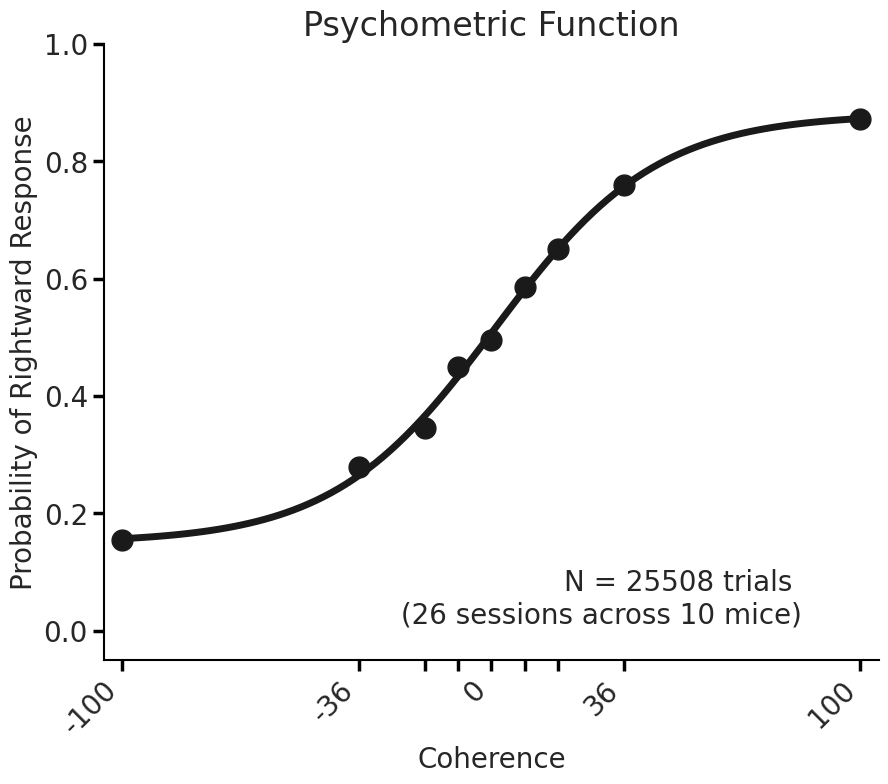

In [19]:
x, y, model, x_hat, y_hat = pmf_utils.get_psychometric_data(get_pulse_data(data, 0), model_type=main_config.psych_model, x_model_range=[-100, 100])

fig, ax = plt.subplots(figsize=(10, 8))
ax.plot(x, y, "k", marker="o", ms=15, alpha=1, linestyle="None")
ax.plot(x_hat, y_hat, "k", lw=5, ls="-", alpha=1)

# Formatting
ax.set_xlabel("Coherence", fontsize=20)
ax.set_ylabel("Probability of Rightward Response", fontsize=20)
ax.set_title("Psychometric Function", fontsize=24)
ax.set_ylim(-0.05, 1.0)

ax.set_xlim(-105, 105)
tick_positions = [-100, -36, -18, -9, 0, 9, 18, 36, 100]
tick_labels = ["-100", "-36", "", "", "0", "", "", "36", "100"]
ax.set_xticks(tick_positions)
ax.set_xticklabels(tick_labels, rotation=45, ha="right")

# Tick params and spines
ax.tick_params(axis="both", which="major", labelsize=20, width=2.5, length=8, color="black", direction="out", bottom=True, left=True, top=False, right=False)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
for s in ["bottom", "left"]:
    ax.spines[s].set_linewidth(1.5)
    ax.spines[s].set_color("black")
ax.grid(False)

textstr = "N = 25508 trials \n (26 sessions across 10 mice)"
props = dict(boxstyle="round", facecolor="white", alpha=0.8, edgecolor=None)
ax.text(0.9, 0.05, textstr, transform=ax.transAxes, fontsize=20, verticalalignment="bottom", horizontalalignment="right", bbox=props)


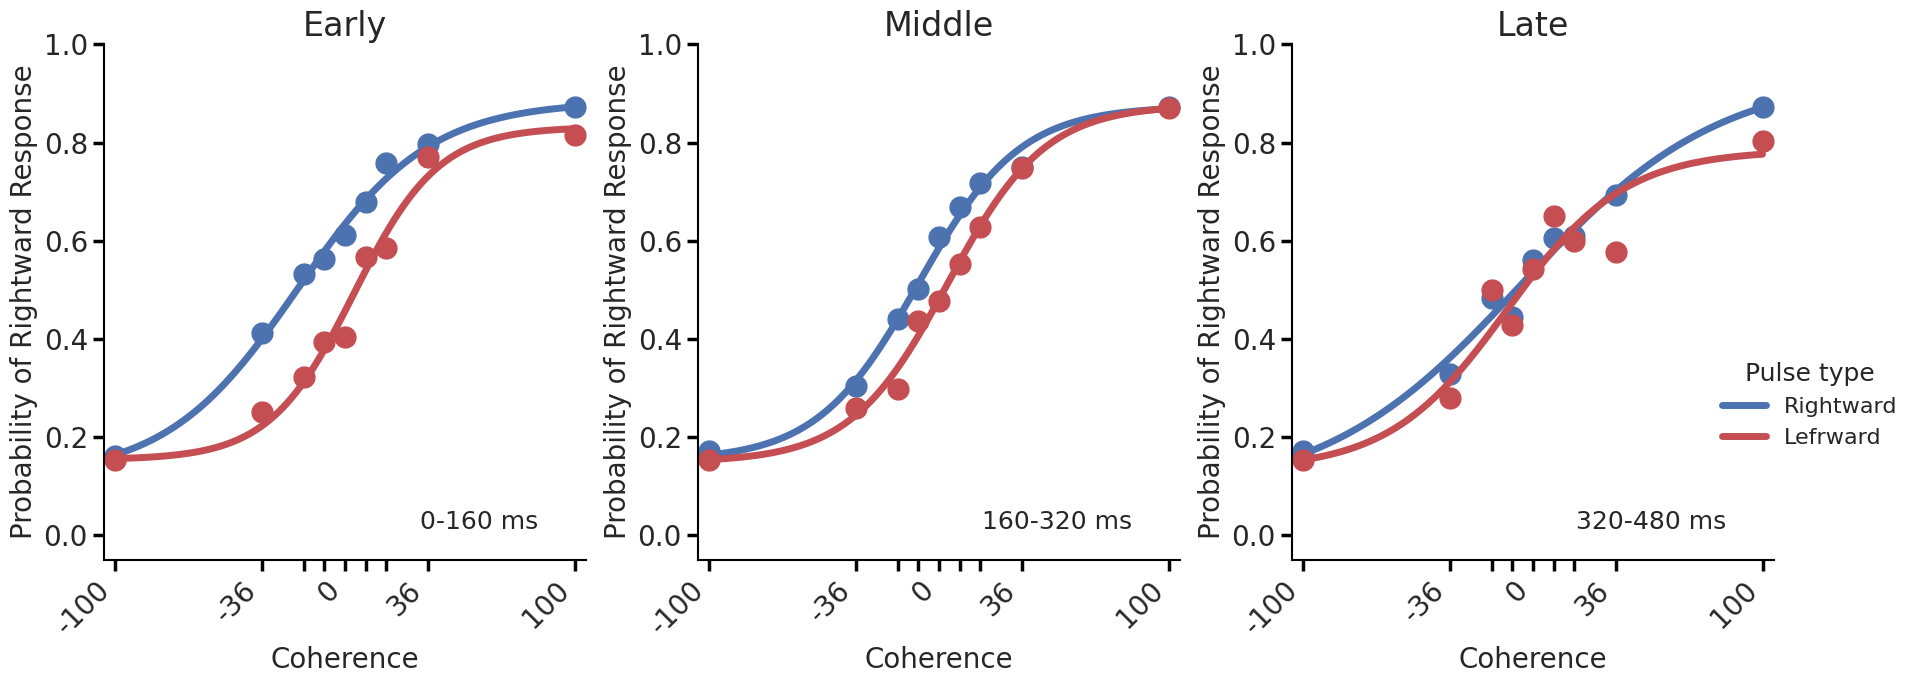

In [20]:


# run utils.get_psychometric_curve function for each subset of pulse_type
psych_curves = {}

for pulse_type in data.pulse_type.unique():


    x, y, model, x_hat, y_hat = pmf_utils.get_psychometric_data(get_pulse_data(data, pulse_type), model_type=main_config.psych_model, x_model_range=[-100, 100])

    psych_curves[pulse_type] = {
        "x": x,
        "y": y,
        "model": model,
        "x_hat": x_hat,
        "y_hat": y_hat,
    }

fig, axs = plot_pulse_psych(psych_curves, legend=True, ms=15, lw=5, plot_zero=False);


plt.savefig(Path(dir_config.project_dir, "dissemination", "poster", "pulse_effect_on_psych.svg"), bbox_inches="tight")
plt.savefig(Path(dir_config.project_dir, "dissemination", "poster", "pulse_effect_on_psych.png"), bbox_inches="tight")

## Kiani 2008

### Effect of Pulse and Time

In [21]:
psych_curves, params, params_se = get_pulse_time_psych_data(data)

In [22]:
def get_fit_summary(params, param_se):

    fit_summary = {}
    for param_name in params:
        coef = params[param_name]
        se = param_se[param_name]
        z_score = coef / se
        p_value = 2 * (1 - stats.norm.cdf(abs(z_score)))
        significant = (p_value < 0.05).astype(int)  # cast boolean to 0/1

        fit_summary[param_name] = {"coef": np.round(coef, 6), "std_err": np.round(se, 6), "z_score": np.round(z_score, 6), "p_value": np.round(p_value, 6), "significant": significant}

    fit_summary = pd.DataFrame(fit_summary).T
    print("\n📊 Fit summary:\n", fit_summary)
    return fit_summary

fit_summary = get_fit_summary(params, params_se)



📊 Fit summary:
               coef   std_err    z_score   p_value  significant
alpha_1   0.487439  1.261944   0.386260  0.699304          0.0
alpha_2  17.111473  2.483883   6.889002  0.000000          1.0
alpha_3   1.723482  0.633325   2.721322  0.006502          1.0
alpha_4  -5.274302  1.332617  -3.957853  0.000076          1.0
beta_1    0.047484  0.002839  16.724212  0.000000          1.0
beta_2    0.000577  0.005755   0.100343  0.920072          0.0
beta_3   -0.003093  0.001550  -1.995978  0.045936          1.0
beta_4   -0.001492  0.002986  -0.499541  0.617398          0.0
lapse     0.150080  0.011318  13.260385  0.000000          1.0
gamma     0.130482  0.010921  11.948028  0.000000          1.0


In [23]:
def plot_pulse_params(pulses, fit_summary, param, color, label, marker="o", markersize=10, lw=3, elinewidth=2, capsize=6):
    # Compute y-values
    y_vals = [get_param_and_se(p, fit_summary, param) for p in pulses]

    # Compute y-errors
    y_err = [fit_summary["std_err"][f"{param}_2"] + abs(p) * fit_summary["std_err"][f"{param}_4"] for p in pulses]

    # Plot
    plt.errorbar(pulses, y_vals, yerr=y_err, fmt=marker + "-", color=color, label=label, markersize=markersize, lw=lw, elinewidth=elinewidth, capsize=capsize)


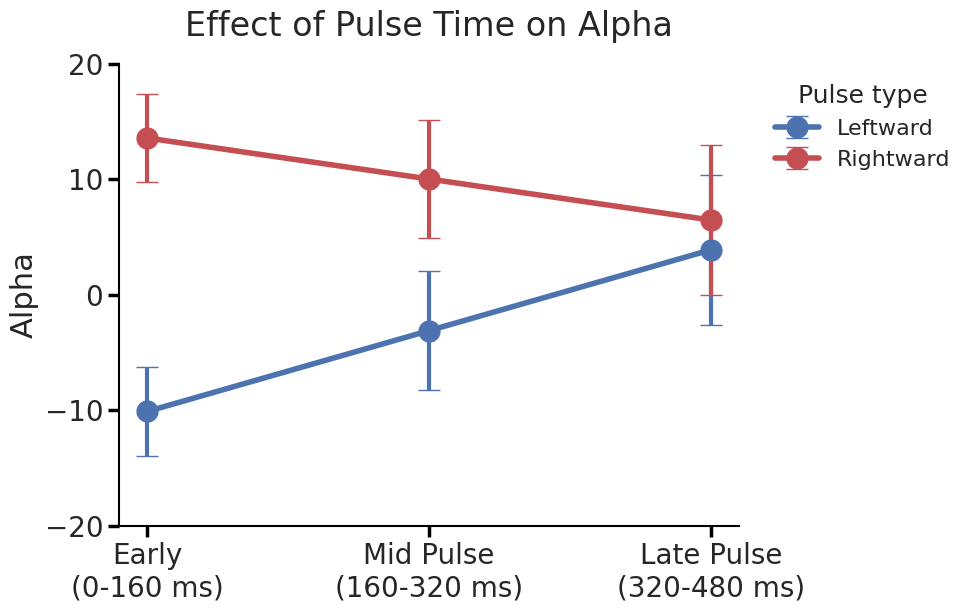

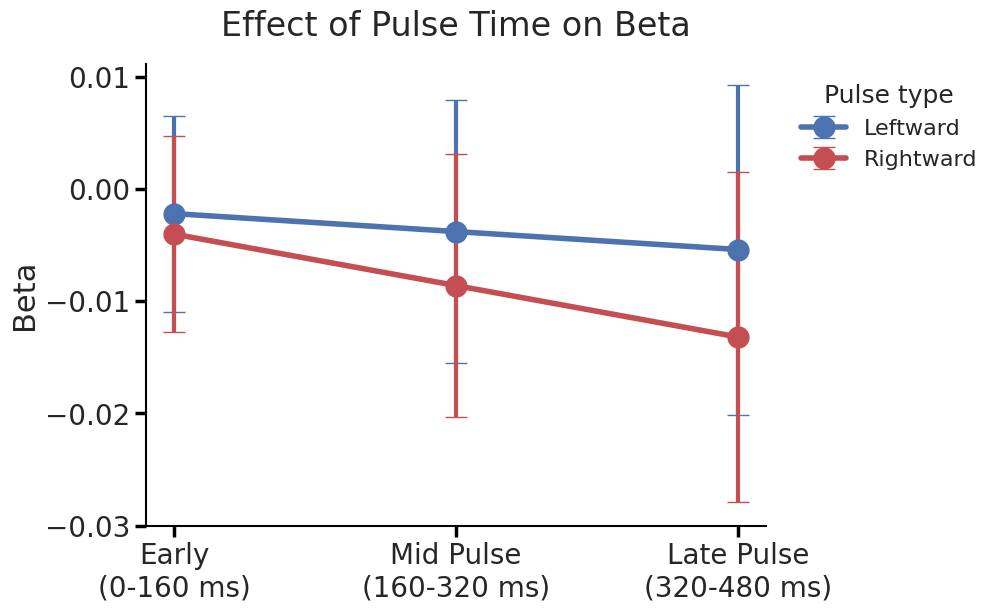

In [24]:
# effect of time on alpha and beta with standard error bars
for param in ["alpha", "beta"]:
    plt.figure(figsize=(8, 6))

    # pulses = [0]
    # plt.errorbar([0], [(get_param_and_se(p, fit_summary, param)) for p in pulses], yerr=[fit_summary["std_err"][f"{param}_2"] + abs(p) * fit_summary["std_err"][f"{param}_4"] for p in pulses],
    #             fmt="o-", color="k", markersize=15, elinewidth=3, lw=4, capsize=8, label="Control")
    # # plot mean and se for control condition as a line across y-axis
    # mean_control = get_param_and_se(0, fit_summary, param)
    # se_control = fit_summary["std_err"][f"{param}_2"]
    # # Mean and SE horizontal band
    # plt.hlines(mean_control, xmin=0.5, xmax=3.5, colors="k", linestyles="dashed", lw=2)
    # plt.fill_betweenx(
    #     [mean_control - se_control, mean_control + se_control],
    #     0.5, 3.5,
    #     color="k", alpha=0.2
    # )



    pulses = [-1, -2, -3]
    plt.errorbar([1,2,3], [(get_param_and_se(p, fit_summary, param)) for p in pulses], yerr=[fit_summary["std_err"][f"{param}_2"] + abs(p) * fit_summary["std_err"][f"{param}_4"] for p in pulses],
                fmt="o-", color="b", markersize=15, elinewidth=3, lw=4, capsize=8, label="Leftward")
    pulses = [1, 2, 3]
    plt.errorbar([1,2,3], [(get_param_and_se(p, fit_summary, param)) for p in pulses], yerr=[fit_summary["std_err"][f"{param}_2"] + abs(p) * fit_summary["std_err"][f"{param}_4"] for p in pulses],
                fmt="o-", color="r", markersize=15, elinewidth=3, lw=4, capsize=8, label="Rightward")

    plt.xticks([1, 2, 3], ["Early\n(0-160 ms)", "Mid Pulse\n(160-320 ms)", "Late Pulse\n(320-480 ms)"])
    if param == "alpha":
        plt.yticks([-20, -10, 0, 10, 20])
    elif param == "beta":
        plt.yticks([-0.03, -0.02, -0.01, 0, 0.01])
    plt.title("Effect of Pulse Time on " + param.capitalize(), fontsize=24, pad=20)
    # plt.xlabel("Pulse Time", fontsize=22)
    plt.ylabel(param.capitalize(), fontsize=22)
    # no grid, no top/right spines


    plt.legend(title="Pulse type", title_fontsize=18, bbox_to_anchor=(1.025, 1), loc="upper left", fontsize=16, frameon=False)

    plt.tick_params(axis="both", which="major", labelsize=20, width=2.5, length=8, color="black", direction="out", bottom=True, left=True)

    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['top'].set_visible(False)
    for dir in ['left', 'bottom']:
        plt.gca().spines[dir].set_linewidth(1.5)
        plt.gca().spines[dir].set_color('black')
    plt.grid(False)


    # plt.savefig(Path(dir_config.project_dir, "dissemination", "poster", f"pulse_effect_on_{param}.svg"), bbox_inches="tight")
    # plt.savefig(Path(dir_config.project_dir, "dissemination", "poster", f"pulse_effect_on_{param}.png"), bbox_inches="tight")


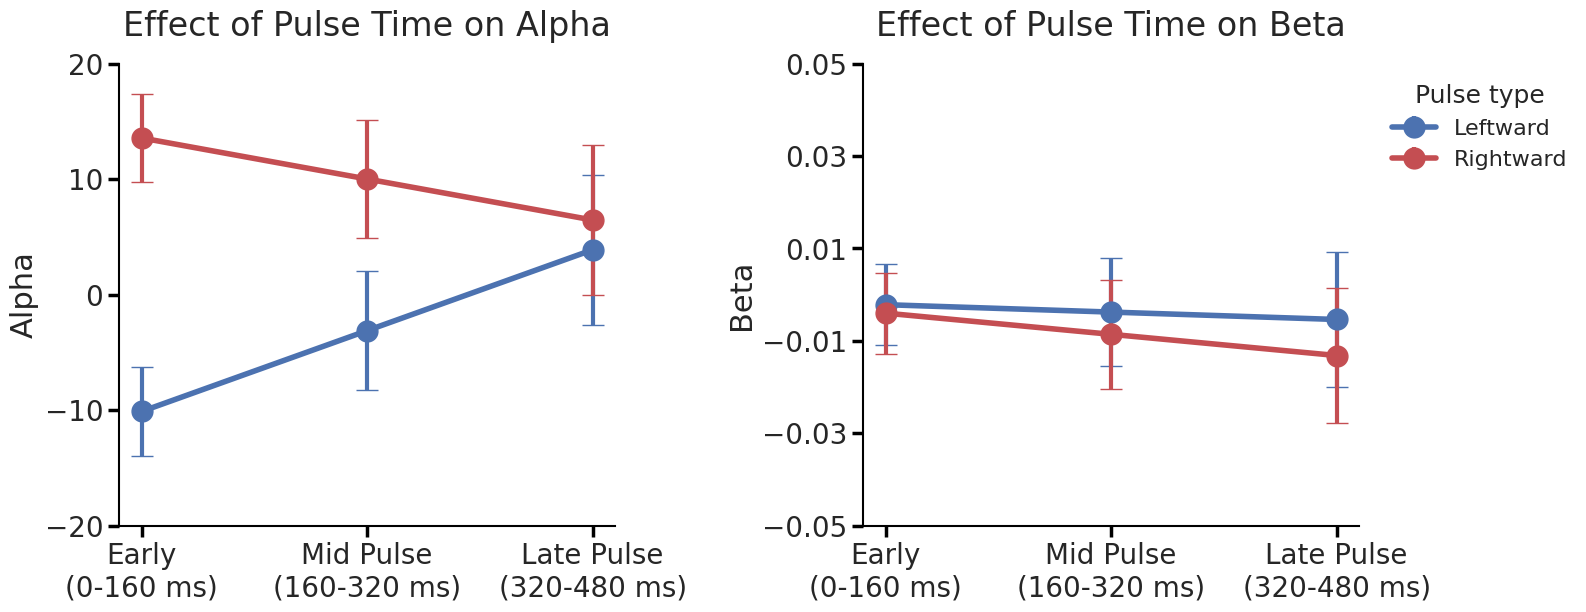

In [35]:
# effect of time on alpha and beta with standard error bars

fig, axs = plt.subplots(1, 2, figsize=(16, 6))
# add gap between subplots
plt.subplots_adjust(wspace=0.5)

for param in ["alpha", "beta"]:

    plt.subplot(1, 2, 1 if param == "alpha" else 2)

    pulses = [-1, -2, -3]
    plt.errorbar(
        [1, 2, 3],
        [(get_param_and_se(p, fit_summary, param)) for p in pulses],
        yerr=[fit_summary["std_err"][f"{param}_2"] + abs(p) * fit_summary["std_err"][f"{param}_4"] for p in pulses],
        fmt="o-",
        color="b",
        markersize=15,
        elinewidth=3,
        lw=4,
        capsize=8,
        # label="Leftward",
    )
    pulses = [1, 2, 3]
    plt.errorbar(
        [1, 2, 3],
        [(get_param_and_se(p, fit_summary, param)) for p in pulses],
        yerr=[fit_summary["std_err"][f"{param}_2"] + abs(p) * fit_summary["std_err"][f"{param}_4"] for p in pulses],
        fmt="o-",
        color="r",
        markersize=15,
        elinewidth=3,
        lw=4,
        capsize=8,
        # label="Rightward",
    )

    plt.tick_params(axis="both", which="major", labelsize=20, width=2.5, length=8, color="black", direction="out", bottom=True, left=True)


    plt.xticks([1, 2, 3], ["Early\n(0-160 ms)", "Mid Pulse\n(160-320 ms)", "Late Pulse\n(320-480 ms)"])
    if param == "alpha":
        plt.yticks([-20, -10, 0, 10, 20])
    elif param == "beta":
        plt.yticks([-0.05, -0.03, -0.01, 0.01, 0.03, 0.05])
        plt.ylim(-0.05, 0.05)
    plt.title("Effect of Pulse Time on " + param.capitalize(), fontsize=24, pad=20)
    # plt.xlabel("Pulse Time", fontsize=22)
    plt.ylabel(param.capitalize(), fontsize=22)
    # no grid, no top/right spines


    plt.gca().spines["right"].set_visible(False)
    plt.gca().spines["top"].set_visible(False)
    for dir in ["left", "bottom"]:
        plt.gca().spines[dir].set_linewidth(1.5)
        plt.gca().spines[dir].set_color("black")
    plt.grid(False)

plt.errorbar([],[],[],fmt="o-",color="b",markersize=15,elinewidth=3,lw=4,capsize=8,label="Leftward")
plt.errorbar([], [], [], fmt="o-", color="r", markersize=15, elinewidth=3, lw=4, capsize=8, label="Rightward")
plt.legend(title="Pulse type", title_fontsize=18, bbox_to_anchor=(1.025, 1), loc="upper left", fontsize=16, frameon=False)


# plt.savefig(Path(dir_config.project_dir, "dissemination", "poster", f"pulse_effect_on_{param}.svg"), bbox_inches="tight")
    # plt.savefig(Path(dir_config.project_dir, "dissemination", "poster", f"pulse_effect_on_{param}.png"), bbox_inches="tight")


-3.268027 -1 1 3.268027
-3.268027 -1 2 6.536054
-3.268027 -1 3 9.804081
-3.268027 1 1 -3.268027
-3.268027 1 2 -6.536054
-3.268027 1 3 -9.804081


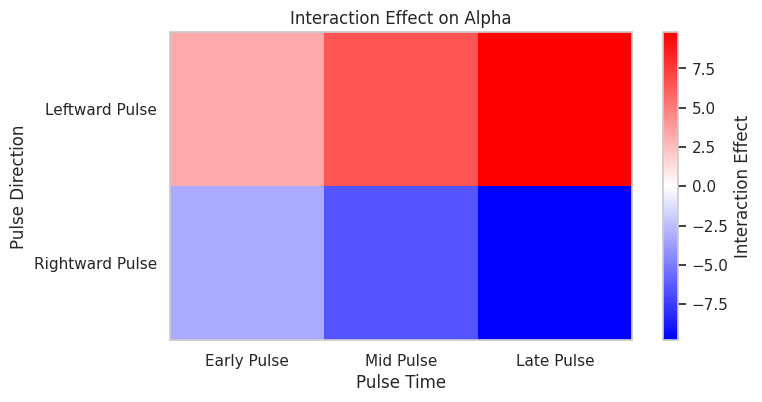

-0.000847 -1 1 0.000847
-0.000847 -1 2 0.001694
-0.000847 -1 3 0.002541
-0.000847 1 1 -0.000847
-0.000847 1 2 -0.001694
-0.000847 1 3 -0.002541


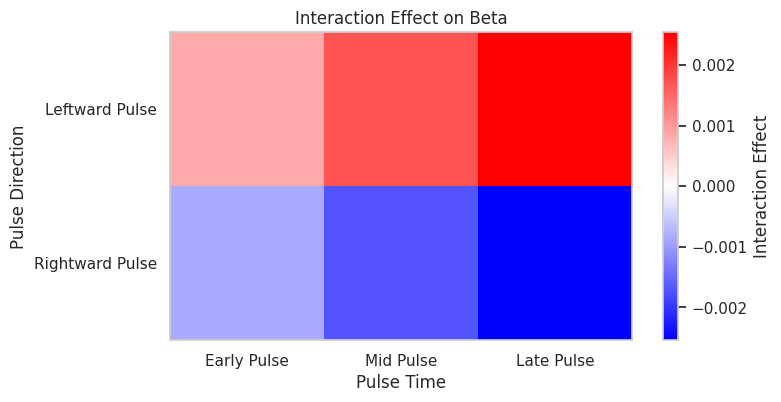

In [34]:
# plot interaction effect on alpha and beta as a 2x3 heatmap
for param in ["alpha", "beta"]:
    interaction_effects = np.zeros((2, 3))
    for i, pulse_dir in enumerate([-1, 1]):
        for j, pulse_time in enumerate([1, 2, 3]):
            interaction_effects[i, j] = fit_summary["coef"][f"{param}_4"] * pulse_dir * pulse_time
            print(fit_summary["coef"][f"{param}_4"], pulse_dir, pulse_time, interaction_effects[i, j])

    plt.figure(figsize=(8, 4))
    plt.imshow(interaction_effects, cmap="bwr", vmin=-np.max(np.abs(interaction_effects)), vmax=np.max(np.abs(interaction_effects)))
    plt.colorbar(label="Interaction Effect")
    plt.xticks([0, 1, 2], ["Early Pulse", "Mid Pulse", "Late Pulse"])
    plt.yticks([0, 1], ["Leftward Pulse", "Rightward Pulse"])
    plt.title(f"Interaction Effect on {param.capitalize()}")
    plt.xlabel("Pulse Time")
    plt.ylabel("Pulse Direction")
    plt.grid(False)
    plt.show()